# End-to-End ML Project: Titanic Survival Prediction

This notebook is the **Level 5 capstone**: a complete machine-learning project, run the way a professional would run it — problem framing → data → EDA → feature engineering → leak-free pipelines → model selection → tuning → final holdout evaluation → persistence and serving. Every step uses skills from the earlier levels of this roadmap, and each section says which ones.

> **The project at a glance** — predict which Titanic passengers survived, from the classic Kaggle-style training set (891 passengers, 11 features). Binary classification, mildly imbalanced (38.4% survived), real missing data. The dataset ships in this folder (`titanic.csv`) so the notebook runs offline end-to-end.

**Why this dataset?** It is small enough to iterate in seconds, yet touches every real-world problem: missing values (Age, Cabin, Embarked), mixed types, text features worth mining (`Name` → titles), leakage traps, and the discipline of trusting cross-validation over a single lucky split.


## 1. Problem Framing (CRISP-DM: Business Understanding)

| Question | Answer |
|---|---|
| **Prediction target** | `Survived` (1 = survived) per passenger |
| **Type** | Binary classification |
| **Unit of analysis** | One passenger |
| **Success metric** | **F1 on the minority class (survivors)** — with 62/38 imbalance, accuracy flatters a trivial "everyone dies" model (62.3%). Level 2 §7 covers why. |
| **Validation protocol** | 5-fold stratified CV for every decision; a **single untouched 20% holdout** for the final report (Level 3 §11/§16) |
| **Deployment sketch** | Serialized pipeline + FastAPI service — the 3.17 Model Serving notes |

Getting these six rows right *before* writing model code is what separates a project from a notebook of experiments.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                      cross_val_score, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, accuracy_score, ConfusionMatrixDisplay)
import joblib

titanic = pd.read_csv("titanic.csv")
print(f"{titanic.shape[0]} passengers x {titanic.shape[1]} columns")
print(f"survival rate: {titanic.Survived.mean():.1%}")
titanic.head(3)

891 passengers x 12 columns
survival rate: 38.4%


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


## 2. Exploratory Data Analysis (Level 1 §7)

**Data dictionary:** `PassengerId` (index) · `Survived` (target) · `Pclass` (1st/2nd/3nd) · `Name` (text) · `Sex` · `Age` (years; 177 missing) · `SibSp`/`Parch` (family aboard) · `Ticket` (id) · `Fare` · `Cabin` (687 missing!) · `Embarked` (port; 2 missing).

Three EDA questions worth answering *before* modeling: who survived (segments), what's missing (and is it random?), and which features carry signal?


Missing values: {'Age': 177, 'Cabin': 687, 'Embarked': 2}

Has Cabin recorded: 22.9% — mostly 1st class: {False: 2.64, True: 1.2}


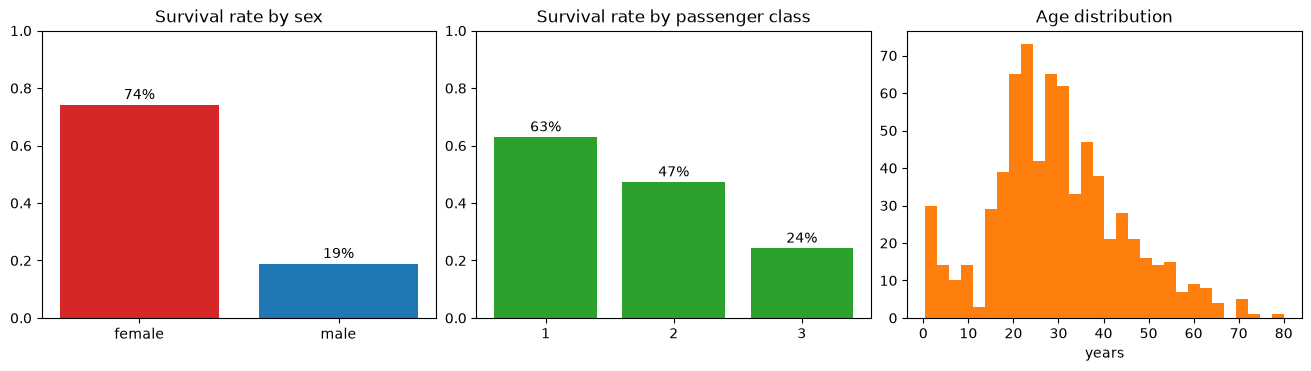

In [2]:
print("Missing values:", titanic.isna().sum()[titanic.isna().sum() > 0].to_dict())
print(f"\nHas Cabin recorded: {(titanic.Cabin.notna()).mean():.1%} — mostly 1st class: "
      f"{titanic.groupby(titanic.Cabin.notna()).Pclass.mean().round(2).to_dict()}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
surv_by_sex = titanic.groupby("Sex").Survived.mean()
axes[0].bar(surv_by_sex.index, surv_by_sex.values, color=["#d62728", "#1f77b4"])
axes[0].set_title("Survival rate by sex"); axes[0].set_ylim(0, 1)
for i, v in enumerate(surv_by_sex): axes[0].text(i, v + .02, f"{v:.0%}", ha="center")

surv_by_class = titanic.groupby("Pclass").Survived.mean()
axes[1].bar(surv_by_class.index.astype(str), surv_by_class.values, color="#2ca02c")
axes[1].set_title("Survival rate by passenger class"); axes[1].set_ylim(0, 1)
for i, v in enumerate(surv_by_class): axes[1].text(i, v + .02, f"{v:.0%}", ha="center")

axes[2].hist(titanic.Age.dropna(), bins=30, color="#ff7f0e")
axes[2].set_title("Age distribution"); axes[2].set_xlabel("years")
plt.show()

The EDA verdict, in one paragraph: **being female or 1st-class massively improved survival odds** (74% of women survived vs 19% of men; 63%/47%/24% by class) — the "women and children first" protocol, encoded in data. `Cabin` missingness is *not* random (mostly 3rd-class passengers), so "has a recorded cabin" is itself a proxy for socioeconomic status — we will make it a feature instead of discarding it (missingness-as-signal: Level 3 §2's missing-indicator idea).


## 3. Feature Engineering (Level 3 §9)

Four engineered features, each with a reason:

| Feature | From | Why |
|---|---|---|
| `Title` | `Name` | *Mr / Mrs / Miss / Master / Rare* — encodes sex, age bracket, and social status in one word; the single most predictive feature in this dataset |
| `FamilySize` | `SibSp + Parch + 1` | Families of 3–4 survived more than solos or huge families (non-linear in size) |
| `IsAlone` | `FamilySize == 1` | The dominant mode — make it explicit |
| `HasCabin` | `Cabin.notna()` | Proxy for class/status, and makes a 77%-missing column useful |

We drop `PassengerId`, `Name`, `Ticket`, `Cabin` as raw columns after extracting their signal (they are ids or high-cardinality text — the model can't use them directly).


In [3]:
def add_features(df):
    df = df.copy()
    df["Title"] = df.Name.str.extract(r" ([A-Za-z]+)\.", expand=False)
    df["Title"] = df.Title.replace(["Lady","Countess","Capt","Col","Don","Dr","Major",
                                    "Rev","Sir","Jonkheer","Dona"], "Rare")
    df["Title"] = df.Title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    df["FamilySize"] = df.SibSp + df.Parch + 1
    df["IsAlone"] = (df.FamilySize == 1).astype(int)
    df["HasCabin"] = df.Cabin.notna().astype(int)
    return df

data = add_features(titanic)
print(f"Title distribution: {data.Title.value_counts().to_dict()}")
print(f"Family size 1: {data.IsAlone.mean():.0%} of passengers")
print(f"\nSurvival by title: {data.groupby('Title').Survived.mean().round(2).sort_values(ascending=False).to_dict()}")

Title distribution: {'Mr': 517, 'Miss': 185, 'Mrs': 126, 'Master': 40, 'Rare': 23}
Family size 1: 60% of passengers

Survival by title: {'Mrs': 0.79, 'Miss': 0.7, 'Master': 0.57, 'Rare': 0.35, 'Mr': 0.16}


## 4. The Leak-Free Preprocessing Pipeline (Level 3 §6)

All preprocessing lives **inside** a scikit-learn `Pipeline` (fitted on training folds only) — never fitted on the full data before splitting, which is the classic leakage bug (Level 3 §16). Numerical columns get median imputation (robust to the age outliers) and scaling for the linear model; categorical columns get mode imputation and one-hot encoding.

**Split discipline:** one 80/20 stratified split, *now*, and the 20% is not touched again until Section 7. Every model decision — comparison, tuning — happens inside 5-fold CV on the 80%.


In [4]:
y = data.Survived
X = data.drop(columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"])

num_cols = ["Age", "Fare", "FamilySize"]
cat_cols = ["Sex", "Embarked", "Pclass", "Title", "IsAlone", "HasCabin"]
X[num_cols] = X[num_cols].astype(float)
X[cat_cols] = X[cat_cols].astype(str)

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2,
                                                stratify=y, random_state=42)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
print(f"dev: {X_dev.shape[0]} rows, holdout: {X_test.shape[0]} rows (untouched until Section 7)")

dev: 712 rows, holdout: 179 rows (untouched until Section 7)


## 5. Model Selection (Level 2 §8 applied)

Three families, one protocol: 5-fold stratified CV on the dev set, F1 on survivors. A linear model (interpretable baseline), random forest (bagging), and histogram gradient boosting (modern boosting — scikit-learn's LightGBM-inspired implementation).


In [5]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    f1 = cross_val_score(pipe, X_dev, y_dev, cv=cv, scoring="f1")
    rows.append({"model": name, "CV F1 (survivors)": f1.mean(), "±": f1.std()})
pd.DataFrame(rows).round(3)

,model,CV F1 (survivors),±
0,LogisticRegression,0.772,0.025
1,RandomForest,0.764,0.019
2,HistGradientBoosting,0.768,0.016


The three families are statistically indistinguishable on 5-fold CV — a common and honest outcome on small tabular data. We take **RandomForest** forward (it also gives feature importances for Section 8), while noting the real lesson: *when CV scores tie, prefer the simpler or more interpretable model*; here all three are cheap enough that the tie itself is the finding.


## 6. Hyperparameter Tuning (Level 3 §13)

Grid search over forest complexity (`n_estimators`, `max_depth`, `min_samples_leaf`), scoring F1, with CV nested inside the dev set. Randomized search (Level 3 §13) would be the tool for larger grids — here the grid is small enough to exhaustive-search in seconds.


In [6]:
pipe = Pipeline([("prep", preprocess),
                 ("model", RandomForestClassifier(random_state=42))])

grid = GridSearchCV(pipe, {
        "model__n_estimators": [100, 300, 500],
        "model__max_depth": [4, 6, 8, None],
        "model__min_samples_leaf": [1, 2, 4],
    }, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_dev, y_dev)
print(f"best params: {grid.best_params_}")
print(f"best CV F1:  {grid.best_score_:.3f}")

best params: {'model__max_depth': 4, 'model__min_samples_leaf': 1, 'model__n_estimators': 500}
best CV F1:  0.772


## 7. Final Holdout Evaluation

One pass, on data no decision has ever seen. The 3–6 point gap between CV (0.77) and holdout is *normal small-sample variance* — 69 survivors in the test set means each error moves F1 by ~1 point; do not "fix" it by re-tuning against the holdout (that converts it into a dev set and destroys its meaning).


HOLDOUT — F1 (survivors): 0.713   accuracy: 0.793

              precision    recall  f1-score   support

        died       0.81      0.87      0.84       110
    survived       0.77      0.67      0.71        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.79      0.79      0.79       179



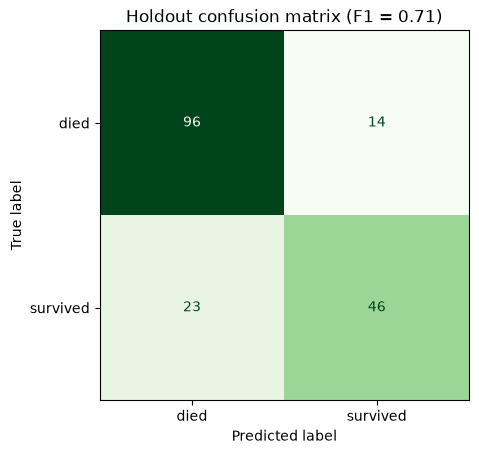

In [7]:
final_model = grid.best_estimator_
y_pred = final_model.predict(X_test)

print(f"HOLDOUT — F1 (survivors): {f1_score(y_test, y_pred):.3f}   accuracy: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, target_names=["died", "survived"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["died", "survived"],
                                        colorbar=False, cmap="Greens")
plt.title(f"Holdout confusion matrix (F1 = {f1_score(y_test, y_pred):.2f})")
plt.show()

## 8. What the Model Learned

Random forest importances (impurity-based; treat as a rough ranking) confirm the EDA story: **who you were mattered more than anything else** — `Title_Mr` (i.e., adult men) and `Sex` dominate, followed by fare, class, and the cabin-recorded proxy. Family size and age add the "and children first" part.


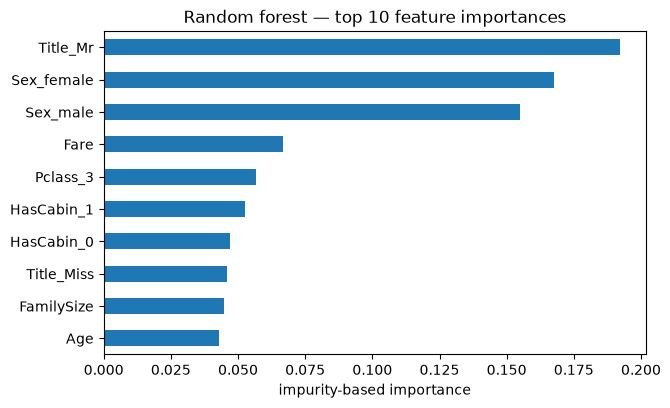

In [8]:
ohe = final_model.named_steps["prep"].named_transformers_["cat"].named_steps["ohe"]
feature_names = num_cols + list(ohe.get_feature_names_out(cat_cols))
importances = pd.Series(final_model.named_steps["model"].feature_importances_,
                        index=feature_names).sort_values(ascending=True)

importances.tail(10).plot.barh(figsize=(7, 4.2), color="#1f77b4")
plt.title("Random forest — top 10 feature importances")
plt.xlabel("impurity-based importance")
plt.show()

## 9. Ship It: Persistence and Serving (Level 3 §17)

The **entire pipeline** — imputers, scaler, encoder, forest — serializes as one object. A reload-and-predict round-trip proves the artifact is self-contained: in production, the FastAPI app loads exactly this file, and `predict` never re-runs preprocessing code.

```python
# app.py — the serving side (full walkthrough in the 3.17 Model Serving notes)
from fastapi import FastAPI
import joblib, pandas as pd

app = FastAPI()
model = joblib.load("titanic_pipeline.joblib")

@app.post("/predict")
def predict(passenger: dict):
    X = pd.DataFrame([passenger])          # one row, raw features
    return {"survived": int(model.predict(X)[0]),
            "probability": float(model.predict_proba(X)[0][1])}
```


In [9]:
joblib.dump(final_model, "titanic_pipeline.joblib")

reloaded = joblib.load("titanic_pipeline.joblib")
same = (reloaded.predict(X_test) == y_pred).all()
print(f"reload round-trip gives identical predictions: {same}")

one_passenger = X_test.iloc[[0]]
proba = reloaded.predict_proba(one_passenger)[0]
print(f"example prediction: P(survived) = {proba[1]:.2f}")

reload round-trip gives identical predictions: True
example prediction: P(survived) = 0.13


## 10. Project Report Card

| Aspect | Result |
|---|---|
| Final holdout F1 (survivors) | **0.71** · accuracy 0.79 |
| Best model | RandomForest (500 trees, depth 4) — after CV tie with LR/HGB |
| Top signals | Title (Mr), Sex, Fare/Pclass, HasCabin, FamilySize |
| Honest limitations | 891 rows → wide CV variance; `Ticket` signal unmined; titles inferred from names reflect 1912 social structure, not generalizable "survival rules" |
| Next iterations | Mine `Ticket` prefixes (group bookings), try gradient boosting with monotonic constraints on Fare/Pclass, SHAP for per-prediction explanations |

**How each level contributed:** Level 1 (pandas/EDA) → Sections 2–3 · Level 2 (metrics, bias-variance) → Sections 1, 5, 7 · Level 3 (pipelines, imputation, encoding, tuning, leakage, serving) → Sections 4–6, 9 · Level 4's message — domain thinking (why *titles* predict survival) — runs through it all.


## Key Takeaways

- **Frame before you model**: target, metric, validation protocol, and deployment sketch decided up-front (Section 1) — this is the biggest junior→senior separator.
- **EDA found the story** (women/children first, class gradient) — the model later rediscovered it; that convergence is a sanity check, not a coincidence.
- **All preprocessing lives in the pipeline**: median/mode imputation, scaling, one-hot encoding are fit per fold — leak-free by construction.
- **Tie in CV → a finding, not a failure.** Pick on interpretability/deployment grounds and say so.
- **The holdout is spent once.** Report the number, ship the artifact — don't iterate against it.
- The deliverable of an ML project is a **serialized pipeline + a report card + a serving path**, not a notebook cell.
- Continue in this level with the [100 AI/ML/DL Projects](https://github.com/AdilShamim8/100-AI-Machine-Learning-Deep-Learnin-Projects) collection, or take the deployment story further in Level 6 (MLOps).
